# OBWIEDNIA
Obwiednia sygnału jest pojęciem nieco trudnym do zdefiniowania, gdyż z jednej strony możemy mówić o funkcji czasu zmieniajacej się znacznie wolnej niż sygnał. Z drugiej strony, można również powiedzieć, że jest to ograniczenie pewnej krzywej.

Najbardziej naiwnym podejściem do tworzenia obwiedni jest branie wartości maksymalnych/minimalnych w zadanym oknie. O ile podejście takie nie jest używane w praktyce, może jednak w łatwy sposób pokazać ideę tworzenia obwiedni sygnału.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<Axes: >

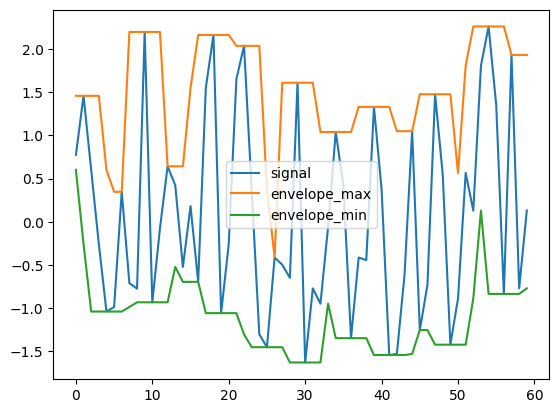

In [3]:
signal = np.random.normal(0,1,60)
envelope_window = 5
df = pd.DataFrame(signal,columns=['signal'])
df['envelope_max'] = df['signal'].rolling(envelope_window, 1, center=True).max()
df['envelope_min'] = df['signal'].rolling(envelope_window, 1, center=True).min()
df.plot()

<Axes: >

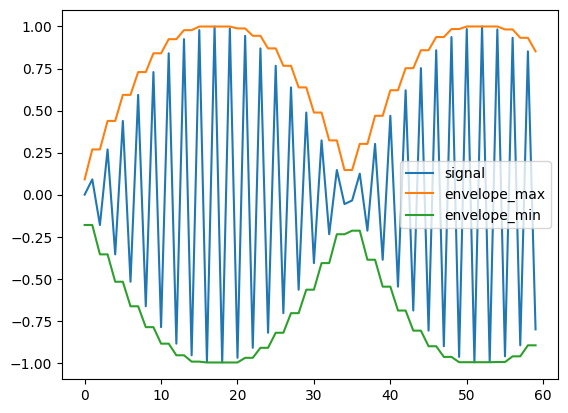

In [4]:
signal = np.sin(np.linspace(0,180,60))
envelope_window = 5
df = pd.DataFrame(signal,columns=['signal'])
df['envelope_max'] = df['signal'].rolling(envelope_window, 1, center=True).max()
df['envelope_min'] = df['signal'].rolling(envelope_window, 1, center=True).min()
df.plot()

Zastosowania obwiedni:
    - uogólnienie amplitudy
    - odtwarzanie sygnału bazowego

Głównym elementem, który słyszymy, gdy ktos mówi, są FORMANTY, czyli  pasma częstotliwości w dźwięku, w granicach którego wszystkie tony składowe ulegają szczególnemu wzmocnieniu. Formanty będą stanowić maksima obwiedni sygnału. Zbior formantów odpowiada za barwę dźwięku.
Ilustracja: Spektrogram przedstawiający samogłoski (i, u, a) w amerykańskiej odmianie języka angielskiego i ich formanty F1 i F2 (żródło: https://pl.wikipedia.org/wiki/Formant_(akustyka) [dostęp: 09.12.2019]).

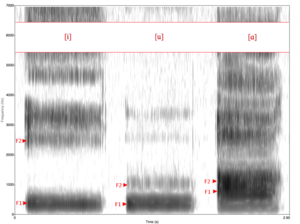

Poniższy kod dotyczący tworzenia obwiedni pochodzi stąd: https://github.com/katejarne/Envelope_Code i jest autorstwa Cecilii Jarne. Dla zainteresowanych jej pełną pracą nad obwiedniami odsyłam do artykułu: "Simple empirical algorithm to obtain signal envelope in three steps"

Względem oryginału w kodzie nastąpiły niewielkie zmiany, dotyczące przede wszystkim sposobu rysowania obwiedni. Dla naszych celów wystarczający będzie jeden sposób tworzenia obwiedni. Ponadto, przydatne moze okazać się również jej wypełnienie, co jest uzyskane z pomocą funkcji fill_between (w ogólności sposób jej uzycia zbliżony do funkcji plot())

In [9]:
######################################################################################################
#                                                                                                    #
# 1)Reads wav 1 or 2 ch and plot signal.                                                             #
# 2)Estimate envelope and sonogram                                                                   #
# 3)Make consecutive plots of "step_time" size in file with current wav name for each file in r_dir  #
#                                                                                                    #
#                                         C. Jarne 05-01-2017 V1.0                                   #
######################################################################################################

# libraries
import numpy as np
import scipy
import os
import scipy.stats as stats

from scipy.io import wavfile
import wave, struct
import matplotlib.pyplot as pp

from pylab import *
import scipy.signal.signaltools as sigtool
import scipy.signal as signal
from scipy.fftpack import fft

# Here directory (put the name and path). Directory only with .wav files

#r_dir='./wavs'
r_dir = '/content/drive/MyDrive/wavs'

# Parameters

Fmax         = 10000 #maximum frequency for the sonogram [Hz]
step_time    = 1.2   #len for the time serie segment  [Seconds]->>>>>>>>> Change it to zoom in the signal time!!
w_cut        = 300   #Frequency cut for our envelope implementation [Hz]
w_cut_simple = 150   #Frecuency cut for the low-pass envelope [Hz]


###################################
#1) Function envelope with rms slide window (for the RMS-envelope implementation)

def window_rms(inputSignal, window_size):
    a2 = np.power(inputSignal,2)
    window = np.ones(window_size)/float(window_size)
    return np.sqrt(np.convolve(a2, window, 'valid'))

##################################

#2) Filter is directly implemented in Abs(signal)

##################################
#3) our implementation !

def getEnvelope(inputSignal):
# Taking the absolute value

    absoluteSignal = []
    for sample in inputSignal:
        absoluteSignal.append (abs (sample))

    # Peak detection

    intervalLength = 35 # change this number depending on your Signal frequency content and time scale
    outputSignal = []

    for baseIndex in range (0, len (absoluteSignal)):
        maximum = 0
        for lookbackIndex in range (intervalLength):
            maximum = max (absoluteSignal [baseIndex - lookbackIndex], maximum)
        outputSignal.append (maximum)

    return outputSignal


##################################
#Loop over sound files in directory

for root, sub, files in os.walk(r_dir):
    print(root)
    print(sub)
    print(files)
    files = sorted(files)
    for f in files[1:2]:
        w     = scipy.io.wavfile.read(os.path.join(root, f))
        print (r_dir)
        base=os.path.basename(f)
        print (base)
        dir = os.path.dirname(base)
        if not os.path.exists(dir):
           os.mkdir(base)
        print('-------------------------')

        a=w[1]
        print('sound vector: ')#, w

        i=w[1].size

        print ('vector size in Frames: ',i)

        x     = w[1]
        x_size= x.size
        tt    = w[1]

        #Comment for stero or not
        v1    = np.arange(float (i)/float(2))# not stereo
        #v1    = np.arange(float (i))#/float(2)) #stereo
        c     = np.c_[v1,x]

        print ('vector c:\n' , c)
        print ('vector c1:\n',c[0])

        cc=c.T #transpose

        x = cc[0]
        x1= cc[1]
        x2= cc[1]#2

        print ('First cc comp:\n ', cc[0])
        print ('Second cc comp:\n', cc[1])
        print ('Third cc comp: \n', cc[1])# cc[2] if stereo


        #Low Pass Frequency for Filter definition (envelope case 2)

        W2       = float(w_cut_simple)/w[0] #filter parameter Cut frequency over the sample frequency
        (b2, a2) = signal.butter(1, W2, btype='lowpass')

        #Filter definition for our envelope (3) implementation

        W1       = float(w_cut)/w[0] #filter parameter Cut frequency over the sample frequency
        (b, a)   = signal.butter(4, W1, btype='lowpass')
        aa       = scipy.signal.medfilt(scipy.signal.detrend(x2, axis=-1, type='linear'))
        i        = x.size
        p        = np.arange(i)*float(1)/w[0]


        stop      = i
        step      = i#int(step_time*w[0])
        intervalos= np.arange(0, i,step)

        print( intervalos)
        print('-------------------')
        print('The step: ',step)
        print('-------------------')

        time1=x*float(1)/w[0]

        ##chop time serie##
        for delta_t in intervalos:

            aa_part                   = aa[delta_t:delta_t+step]
            x1_part                   = x2[delta_t:delta_t+step]#or x1
            x2_part                   = x2[delta_t:delta_t+step]

            #envelope implementations
            x1_part_rms               = window_rms(aa,500)##envolvente Rms (second parameter is windows size)
            time_rms                  = np.arange(len(x1_part_rms))*float(1)/w[0]


            #envelope low pass
            filtered_aver_simple      = signal.filtfilt(b2, a2, abs(aa_part))
            filtered_aver_vs_ped_simp = filtered_aver_simple

            # envelope our implementation
            aver                      = getEnvelope(aa_part)
            filtered_aver             = signal.filtfilt(b, a, aver)
            filtered_aver_part        = filtered_aver[delta_t:delta_t+step]

            aver_vs                   = getEnvelope(x2_part)
            filtered_aver_vs          = signal.filtfilt(b, a, aver_vs)
            envelope_part             = filtered_aver
            filtered_aver_vs_part     = filtered_aver_vs[delta_t:delta_t+step]

            #time (to x axis in seconds)

            time_part                 = time1[delta_t:delta_t+step]
            time                      = time1[delta_t:delta_t+step]


            ###################################################

            #Figure definition
            pp.figure(figsize=(14,9.5*0.6))
            pp.title('Sound Signal')
            pp.subplot(2,1,1)

            #Uncoment what envelope you whant to plot

            grid(True)

            #Signal
            #label_S,= pp.plot(x*float(1)/w[0],x1, color='c',label='Time Signal')

            #Abs value of signal
            #pp.plot(x*float(1)/float(w[0]),abs(x1), color='y',label='Absolute value of Time Signal')


            # Low pass filter envelope #
            print(type(time_part))
            print(type(filtered_aver_vs_ped_simp))
            #envelope_1= pp.fill_between(time_part,0,filtered_aver_vs_ped_simp)#, linestyle='--',color='b',label='Low-pass Filter envelope',linewidth=3)

            # Rms envelope #
            #envelope_2,= pp.plot(time_rms+500/w[0],x1_part_rms, linestyle='-',color='k',label='RMS aproach envelope',linewidth=1)

            # Our implementation #
            #envelope_pre,=pp.plot(time_part,aver,color='k',label='Second step for envelope',linewidth=1)# Pre-envelope
            envelope_3= pp.fill_between(time_part,0,filtered_aver_vs, color='r',label='Final Peak aproach  envelope',linewidth=2)


            pp.ylabel('Amplitude [Arbitrary units]')
            pp.xlim([delta_t*float(1)/w[0],(delta_t+step)*float(1)/w[0]+0.001])
            pp.xticks(np.arange(delta_t*float(1)/w[0],(delta_t+step)*float(1)/w[0]+0.001,0.1),fontsize = 12)
            #pp.yticks(np.arange(-15000,15000+5000,5000),fontsize = 12)
            pp.ylim(-20000,20000)
            pp.tick_params( axis='x', labelbottom='off')
            pp.tick_params( axis='y', labelleft='off')

            #pp.legend([label_S,envelope_1,envelope_2,envelope_3],['Time Signal', 'Low-pass Filter envelope','RMS aproach envelope','Final Peak aproach  envelope'],fontsize= 'x-small',loc=4)


            ################################################
            #Sonogram
            pp.subplot(2,1,2)

            grid(True)
            nfft_=int(w[0]*0.010)

            pp.specgram(x1, NFFT=int(w[0]*0.01) , Fs=w[0], noverlap = int(w[0]*0.005),cmap='jet')
            #pp.specgram(x1, NFFT=int(w[0]*0.01) ,  window= scipy.signal.tukey(int(w[0]*0.01)), Fs=w[0], noverlap = int(w[0]*0.005),cmap='jet') #other window
            #pp.xticks(np.arange(0,8+0.001,0.1),fontsize = 12)
            #pp.xlim(0, step_time+0.001)
            pp.xlim([delta_t*float(1)/w[0],(delta_t+step)*float(1)/w[0]+0.001])
            pp.xticks(np.arange(delta_t*float(1)/w[0],(delta_t+step)*float(1)/w[0]+0.001,0.1),fontsize = 12)
            pp.yticks(np.arange(0,Fmax,1000),fontsize = 12)
            pp.ylim(0, Fmax)
            pp.xlabel('Time [Sec]')
            pp.ylabel('Frequency [Hz]')
            #pp.legend("legend",fontsize= 'x-small')
            #pp.tick_params( axis='x', labelbottom='off')

            plt.plot()
            figname = "%s.png" %(str(base)+'/'+str(base)+'_signal_zoom_'+str(delta_t*float(1)/w[0]))
            #pp.savefig(os.path.join(base,figname),dpi=200)
            res=pp.savefig(figname,dpi=200)
            pp.close('all')

            ###############################################################
            #save in plot file txt with data if necesary

            #f_out     = open('plots/%s.txt' %(str(base)+'_'+str(delta_t*float(1)/float(w[0]))), 'w')
            #xxx       = np.c_[time_part,x2_part,filtered_aver,filtered_aver_vs]
            #np.savetxt(f_out,xxx,fmt='%f %f %f %f',delimiter='\t',header="time   #sound   #sound-evelope   #vS-envelope")

        print ('.---All rigth!!!----.')



/content/drive/MyDrive/wavs
[]
['001_K.wav', '002_M.wav', '004_M.wav', '003_K.wav']
/content/drive/MyDrive/wavs
002_M.wav
-------------------------
sound vector: 
vector size in Frames:  433218
vector c:
 [[ 0.00000e+00 -2.90000e+01 -3.80000e+01]
 [ 1.00000e+00 -4.70000e+01 -4.10000e+01]
 [ 2.00000e+00 -3.30000e+01 -2.80000e+01]
 ...
 [ 2.16606e+05  2.99000e+02  2.80000e+02]
 [ 2.16607e+05  3.10000e+02  2.84000e+02]
 [ 2.16608e+05  2.97000e+02  2.71000e+02]]
vector c1:
 [  0. -29. -38.]
First cc comp:
  [0.00000e+00 1.00000e+00 2.00000e+00 ... 2.16606e+05 2.16607e+05
 2.16608e+05]
Second cc comp:
 [-29. -47. -33. ... 299. 310. 297.]
Third cc comp: 
 [-29. -47. -33. ... 299. 310. 297.]
[0]
-------------------
The step:  216609
-------------------
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
.---All rigth!!!----.


# DTW

Głównym zastosowaniem algorytmu Dynamic Time Warping jest badanie podobieństwa dwóch sygnałów o różnym czasie ich trwania.

In [6]:
#!pip install dtw
!pip install "git+https://github.com/pollen-robotics/dtw"

  Cloning https://github.com/pollen-robotics/dtw to /tmp/pip-req-build-nktjowkx
  Running command git clone --filter=blob:none --quiet https://github.com/pollen-robotics/dtw /tmp/pip-req-build-nktjowkx
  Resolved https://github.com/pollen-robotics/dtw to commit 74d9e55621cd4507e88bffa2c777b80fad86f954
  Preparing metadata (setup.py) ... done
  Created wheel for dtw: filename=dtw-1.4.1-py3-none-any.whl size=16039 sha256=6ee513e596a2654f732f0002377fedbff68d4198f2c2a345af1aa83054eb03c0
  Stored in directory: /tmp/pip-ephem-wheel-cache-vnx9yctm/wheels/be/77/39/17ddd9f9b21366807792287c2937f9226c73005169fb2c1ee0
Successfully built dtw


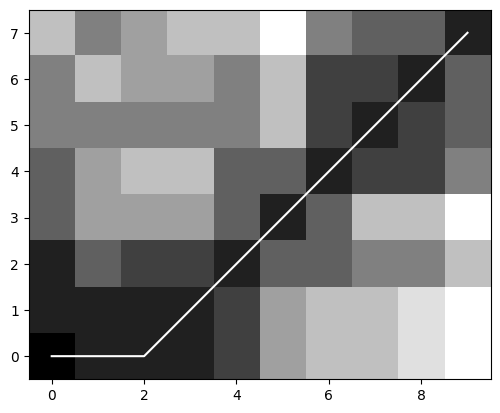

In [10]:
# źródło: https://github.com/pierre-rouanet/dtw

import numpy as np

# We define two sequences x, y as numpy array
# where y is actually a sub-sequence from x
x = np.array([2, 0, 1, 1, 2, 4, 2, 1, 2, 0]).reshape(-1, 1)
y = np.array([1, 1, 2, 4, 2, 1, 2, 0]).reshape(-1, 1)

from dtw import dtw

euclidean_norm = lambda x, y: np.abs(x - y)

d, cost_matrix, acc_cost_matrix, path = dtw(x, y, dist=euclidean_norm)

# You can also visualise the accumulated cost and the shortest path
import matplotlib.pyplot as plt

plt.imshow(acc_cost_matrix.T, origin='lower', cmap='gray', interpolation='nearest')
plt.plot(path[0], path[1], 'w')
plt.show()

Poniżej znajdują się dwa przykłady porównania dźwięków skrzypiec. Pliki zawierające 'A' w nazwie, przedstawiają dźwięk A, odpowiednio pliki z 'D' w nazwie, zawierają dźwięk D zagrany na skrzypcach. Porównaj wykresy dla pierwszego i drugiego przykładu. Wartość, która jest wypisywana to długość ścieżki "różnicy dźwięków", czyli tak naprawdę koszt, zatem chcemy go minimalizować.

/tmp/ipython-input-4123908853.py:11: WavFileWarning: Chunk (non-data) not understood, skipping it.
  signal1 = scipy.io.wavfile.read(file1)


95512.0


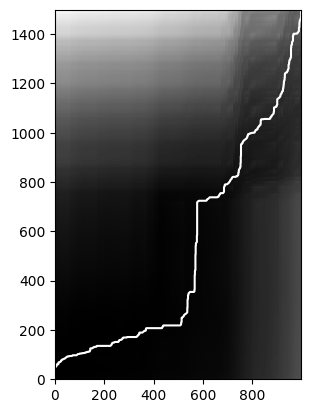

In [11]:
import scipy

### colab paths
file1 = '/content/drive/MyDrive/envelopes/10_de_A_dn_1_nf.wav'
file2 = '/content/drive/MyDrive/envelopes/18_de_A_up_1_nf.wav'

### local paths
#file1 = '.\\envelopes\\10_de_A_dn_1_nf.wav'
#file2 = '.\\envelopes\\18_de_A_up_1_nf.wav'

signal1 = scipy.io.wavfile.read(file1)
signal2 = scipy.io.wavfile.read(file2)

d, cost_matrix, acc_cost_matrix, path = dtw(signal1[1][:1000], signal2[1][:1500], dist=euclidean_norm)
print(d)
plt.imshow(acc_cost_matrix.T, origin='lower', cmap='gray', interpolation='nearest')
plt.plot(path[0], path[1], 'w')
plt.show()

/tmp/ipython-input-902998679.py:9: WavFileWarning: Chunk (non-data) not understood, skipping it.
  signal1 = scipy.io.wavfile.read(file1)


463237.0


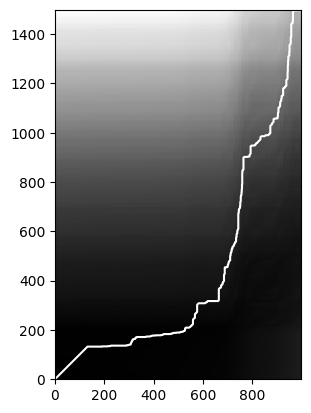

In [12]:
### colab paths
file1 = '/content/drive/MyDrive/envelopes/10_de_A_dn_1_nf.wav'
file2 = '/content/drive/MyDrive/envelopes/10_de_D_dn_1_nf.wav'

### local paths
#file1 = '.\\envelopes\\10_de_A_dn_1_nf.wav'
#file2 = '.\\envelopes\\10_de_D_dn_1_nf.wav'

signal1 = scipy.io.wavfile.read(file1)
signal2 = scipy.io.wavfile.read(file2)

d, cost_matrix, acc_cost_matrix, path = dtw(signal1[1][:1000], signal2[1][:1500], dist=euclidean_norm)
print(d)
plt.imshow(acc_cost_matrix.T, origin='lower', cmap='gray', interpolation='nearest')
plt.plot(path[0], path[1], 'w')
plt.show()

TODO Spróbuj zrobić podobne porównanie na innych dźwiękach. W folderze "digits" znajdziesz cyfry wypowiadane przez różne osoby. Zobacz jak tutaj będzie wyglądało porównanie. Hint: ze względu na to, że tworzona jest macierz N x M, zgodnie z długościami poszczególnych dźwięków, może się okazać, że otrzymacie Memory Error, spróbujcie wówczas zadziałać nad jakimś fragmencie tego dźwięku.

# MFCC

Mel-Frequency Cepstral Coefficients;  W porównaniu do innych metod analizy widmowej sygnału ta technika pozwala na lepsze odwzorowanie ludzkiego systemu słyszenia, który opisany jest nieliniową krzywą.

/tmp/ipython-input-2074673362.py:16: WavFileWarning: Chunk (non-data) not understood, skipping it.
  signal1, y1 = scipy.io.wavfile.read(file1)


[13 18 18 ... 56 59 58]


/usr/local/lib/python3.12/dist-packages/librosa/feature/spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


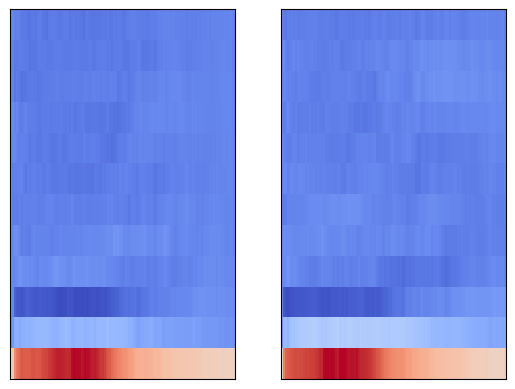

In [13]:
import librosa
from librosa.display import specshow
import matplotlib.pyplot as pp

windowMFCC = 512
windowFFT = 512

### colab paths
file1 = '/content/drive/MyDrive/envelopes/10_de_A_dn_1_nf.wav'
file2 = '/content/drive/MyDrive/envelopes/10_de_D_dn_1_nf.wav'

### local paths
#file1 = '.\\envelopes\\10_de_A_dn_1_nf.wav'
#file2 = '.\\envelopes\\10_de_D_dn_1_nf.wav'

signal1, y1 = scipy.io.wavfile.read(file1)
signal2, y2 = scipy.io.wavfile.read(file2)
print(y1)
pp.subplot(1, 2, 1)
mfcc1 = librosa.feature.mfcc(y=np.array(y1,dtype=float), sr=signal1, n_mfcc=12, hop_length=windowMFCC,n_fft = windowFFT)
specshow(mfcc1)

pp.subplot(1, 2, 2)
mfcc2 = librosa.feature.mfcc(y=np.array(y2,dtype=float), sr=signal2, n_mfcc=12, hop_length=windowMFCC,n_fft = windowFFT)
specshow(mfcc2)

Zastosowanie MFCC: np. rozpoznawanie rozmówcy ( http://www.kms.polsl.pl/mi/pelne_9/31.pdf )

Normalized distance between the two sounds: 21099.152473991555


(-0.5, 110.5)

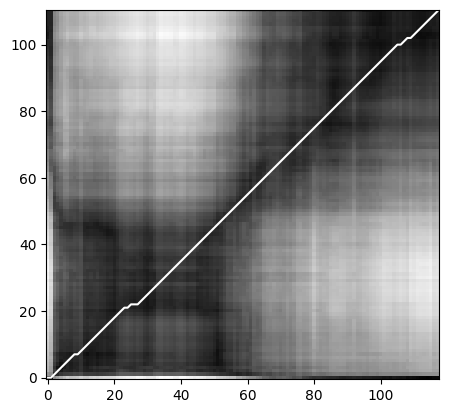

In [14]:
from numpy.linalg import norm
import matplotlib
dist, cost, acc_cost, path = dtw(mfcc1.T, mfcc2.T, dist=lambda x, y: norm(x - y, ord=1))
print('Normalized distance between the two sounds:', dist)

pp.imshow(cost.T, origin='lower', cmap=matplotlib.colormaps['gray'], interpolation='nearest')
pp.plot(path[0], path[1], 'w')
pp.xlim((-0.5, cost.shape[0]-0.5))
pp.ylim((-0.5, cost.shape[1]-0.5))

TODO Podobnie jak wcześniej, spróbuj zrobić MFCC + DTW na innych dźwiękach i przeanalizuj otrzymane wyniki.